# Working with GeoZarr

[GeoZarr](https://github.com/zarr-developers/geozarr-spec) is a set of conventions to describe geospatial raster data stored as [Zarr](https://zarr.dev). In this notebook we use rio-tiler's **experimental** `AsyncGroupReader` to read data from GeoZarr **groups** (hierarchies of groups and arrays, with optional multiscales/overviews).

The reader is built on top of [`zarr-python`](https://zarr.readthedocs.io/) (async API) and [`obstore`](https://developmentseed.org/obstore/) and enables you to:

- list the variables (arrays) available in a GeoZarr hierarchy
- read previews, tiles, parts or features from one or more variables
- select or reduce non-spatial dimensions (e.g. `time`)

Variables are referenced using `{group}:{array_name}` (e.g. `measurements/reflectance:b02`).

**Requirements**

```
python -m pip install "rio-tiler[zarr]" matplotlib
```

> **Note**: the `rio_tiler.experimental` module is subject to change. The reader is **async**, so the cells use top-level `await` (supported in Jupyter).

In [1]:
import numpy
import zarr
from zarr.storage import ObjectStore
from obstore.store import HTTPStore
from matplotlib.pyplot import imshow

from rio_tiler.experimental.zarr import AsyncGroupReader

/Users/vincentsarago/Dev/CogeoTiff/rio-tiler/rio_tiler/experimental/__init__.py:7: RioTilerExperimentalWarning: This module is experimental, its contents are subject to change and deprecation.
  warnings.warn(


## Sentinel-2 L2A (EOPF)

The first dataset is a Sentinel-2 L2A product from the [EOPF](https://zarr.eopf.copernicus.eu) Sample Service, stored as a GeoZarr with multiple resolution levels (r10m, r20m, r60m, ...).

In [2]:
# Sentinel-2 L2A product converted to GeoZarr by the EOPF project.
# Note: the root group doesn't define spatial/proj conventions, so the
# dataset level bounds/crs default to WGS84 and a global extent.
src_path = "https://titiler-benchmark-public.s3.us-east-1.amazonaws.com/geozarrs/S2C_MSIL2A_20260810T125031_N0512_R095_T26SMJ_20260810T155917.zarr"

### Open the GeoZarr

We use an `obstore` HTTP store, wrapped in a zarr `ObjectStore`, to open the **root** group of the dataset.

In [3]:
# Create an obstore HTTP store pointing at the root of the GeoZarr
store = HTTPStore(src_path)
zarr_store = ObjectStore(store=store, read_only=True)

# Open the root group (async API)
geozarr = await zarr.api.asynchronous.open_group(store=zarr_store, mode="r")

### Dataset information

`AsyncGroupReader.info()` returns the dataset level metadata and the list of available variables.

In [4]:
# Initiate the reader with the root group
reader = AsyncGroupReader(input=geozarr)

# Get general information about the dataset
info = await reader.info()
print(info.model_dump_json(indent=2))
print()

# Variables are identified by `{group}:{name}`
print("List of Available Variables")
print([var["long_name"] for var in info.variables])

{
  "bounds": [
    -180.0,
    -90.0,
    180.0,
    90.0
  ],
  "crs": "http://www.opengis.net/def/crs/EPSG/0/4326",
  "driver": "GeoZarr",
  "variables": [
    {
      "name": "b02",
      "group": "measurements/reflectance",
      "long_name": "measurements/reflectance:b02",
      "dimensions": [
        "y",
        "x"
      ],
      "multiscale": true
    },
    {
      "name": "b03",
      "group": "measurements/reflectance",
      "long_name": "measurements/reflectance:b03",
      "dimensions": [
        "y",
        "x"
      ],
      "multiscale": true
    },
    {
      "name": "b04",
      "group": "measurements/reflectance",
      "long_name": "measurements/reflectance:b04",
      "dimensions": [
        "y",
        "x"
      ],
      "multiscale": true
    },
    {
      "name": "b08",
      "group": "measurements/reflectance",
      "long_name": "measurements/reflectance:b08",
      "dimensions": [
        "y",
        "x"
      ],
      "multiscale": true
    },
    {

In [5]:
# Get the metadata of a specific group (CRS, bbox and the arrays for each resolution level)
await reader.get_group_metadata("measurements/reflectance")

{'crs': CRS.from_epsg(32626),
 'bbox': [399965.0, 4290245.0, 509755.0, 4400035.0],
 'transform': None,
 'multiscale': True,
 'arrays': {'b02': [{'array': <AsyncArray object_store://HTTPStore("https://titiler-benchmark-public.s3.us-east-1.amazonaws.com/geozarrs/S2C_MSIL2A_20260810T125031_N0512_R095_T26SMJ_20260810T155917.zarr")/measurements/reflectance/r10m/b02 shape=(10980, 10980) dtype=float32>,
    'crs': CRS.from_epsg(32626),
    'height': 10980,
    'width': 10980,
    'transform': Affine(10.0, 0.0, 399965.0,
           0.0, -10.0, 4400035.0),
    'dimensions': ('y', 'x'),
    'spatial_dims': ['y', 'x'],
    'coordinates': None},
   {'array': <AsyncArray object_store://HTTPStore("https://titiler-benchmark-public.s3.us-east-1.amazonaws.com/geozarrs/S2C_MSIL2A_20260810T125031_N0512_R095_T26SMJ_20260810T155917.zarr")/measurements/reflectance/r20m/b02 shape=(5490, 5490) dtype=float32>,
    'crs': CRS.from_epsg(32626),
    'height': 5490,
    'width': 5490,
    'transform': Affine(20.0,

### Preview

`preview()` returns a low resolution version of the whole variable(s). For multiscale groups, the reader will select the most appropriate resolution level.

Dimensions: ['b', 'y', 'x']
Band Names: ['b1']
Band Descriptions: ['b1']
Array Shape: (1, 915, 915)


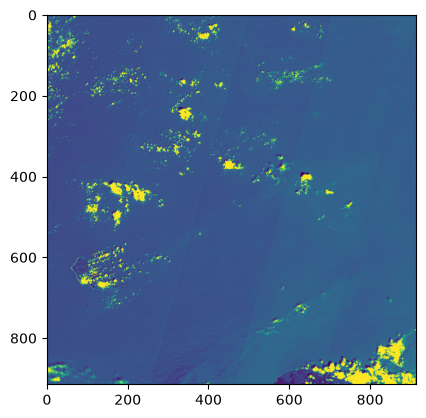

In [6]:
# Read a preview of the variable "measurements/reflectance:b02" (blue band)
# The reader picks the best resolution level (multiscale) for the output size (1024px max by default)
img = await reader.preview(variables=["measurements/reflectance:b02"])
print("Dimensions:", img.dimensions)
print("Band Names:", img.band_names)
print("Band Descriptions:", img.band_descriptions)
print("Array Shape:", img.array.shape)

# Reflectance values are float, rescale 0 -> 0.2 to 0 -> 255 for display
imshow(img.rescale(((0, 0.2),)).data_as_image())

Dimensions: ['variables', 'y', 'x']
Band Descriptions: ['measurements/reflectance:b04', 'measurements/reflectance:b03', 'measurements/reflectance:b02']
Array Shape: (3, 915, 915)


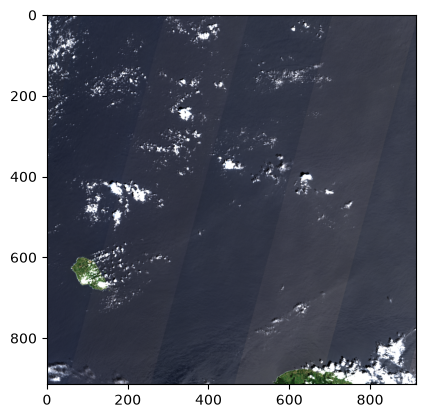

In [7]:
# Create a True Color preview from the red (b04), green (b03) and blue (b02) variables
# Variables are stacked along a new `variables` dimension
img = await reader.preview(
    variables=[
        "measurements/reflectance:b04",
        "measurements/reflectance:b03",
        "measurements/reflectance:b02",
    ]
)
print("Dimensions:", img.dimensions)
print("Band Descriptions:", img.band_descriptions)
print("Array Shape:", img.array.shape)

imshow(img.rescale(((0, 0.2),)).data_as_image())

### Read data for a Feature

`feature()` reads the data intersecting a GeoJSON feature. The returned `ImageData` is in the dataset's CRS and masked outside the geometry.

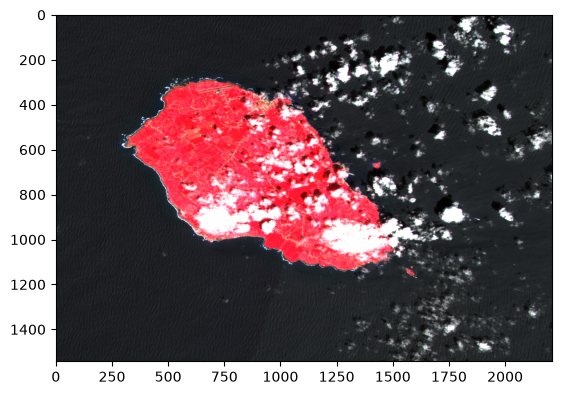

In [8]:
# Area of Interest (GeoJSON Feature, in WGS84)
feat = {
    "type": "Feature",
    "properties": {},
    "geometry": {
        "type": "Polygon",
        "coordinates": [
            [
                [-28.103158369086685, 39.126003460944304],
                [-27.875051234256915, 39.126003460944304],
                [-27.875051234256915, 38.96740726058968],
                [-28.103158369086685, 38.96740726058968],
                [-28.103158369086685, 39.126003460944304],
            ]
        ],
    },
}

# Read the data within the feature as a False Color composite (NIR, Red, Green)
img = await reader.feature(
    feat,
    variables=[
        "measurements/reflectance:b08",
        "measurements/reflectance:b04",
        "measurements/reflectance:b03",
    ],
)
imshow(img.rescale(((0, 0.25),)).data_as_image())

### Band math

Because rio-tiler returns `ImageData` objects, we can use `apply_expression` to compute indices such as the [NDVI](https://en.wikipedia.org/wiki/Normalized_difference_vegetation_index).

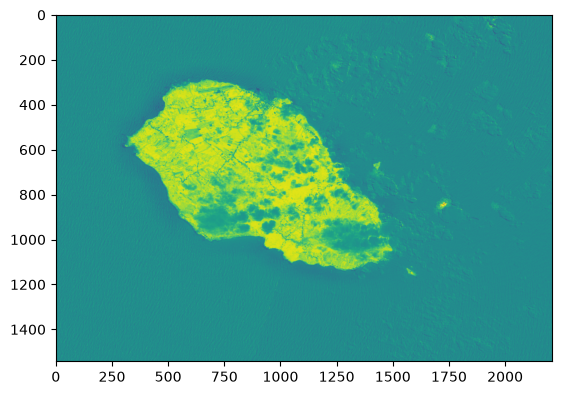

In [9]:
# Read the NIR (b08) and Red (b04) variables within the feature
img = await reader.feature(
    feat,
    variables=["measurements/reflectance:b08", "measurements/reflectance:b04"],
)

# Rename bands so we can use them in the expression
img.band_names = ["nir", "red"]

# Compute the NDVI
img = img.apply_expression("(nir - red) / (nir + red)")

# NDVI values are in the -1 -> 1 range
imshow(img.rescale(((-1, 1),)).data_as_image())

## Multi-temporal Sentinel-1 RTC

The second dataset is a Sentinel-1 Radiometric Terrain Corrected (RTC) datacube, with `ascending` and `descending` groups containing `vv`/`vh` backscatter arrays with a **time** dimension.

In [10]:
# Multi-temporal Sentinel-1 RTC GeoZarr
# Note:
# - the root group doesn't define spatial/proj conventions, so the dataset
#   level bounds/crs default to WGS84 and a global extent
# - variables in the ascending/descending groups (vv/vh) have a time dimension (time, y, x)
src_path = "https://titiler-benchmark-public.s3.us-east-1.amazonaws.com/geozarrs/s1-rtc-32UPB.zarr"

In [11]:
# Create the obstore/zarr stores and open the root group
store = HTTPStore(src_path)
zarr_store = ObjectStore(store=store, read_only=True)
geozarr = await zarr.api.asynchronous.open_group(store=zarr_store, mode="r")

In [12]:
# Initiate the reader
reader = AsyncGroupReader(input=geozarr)

# Get general information about the dataset
info = await reader.info()
print(info.model_dump_json(indent=2))
print()
print("List of Available Variables")
print([var["long_name"] for var in info.variables])

{
  "bounds": [
    -180.0,
    -90.0,
    180.0,
    90.0
  ],
  "crs": "http://www.opengis.net/def/crs/EPSG/0/4326",
  "driver": "GeoZarr",
  "variables": [
    {
      "name": "border_mask",
      "group": "ascending",
      "long_name": "ascending:border_mask",
      "dimensions": [
        "time",
        "y",
        "x"
      ],
      "multiscale": true
    },
    {
      "name": "vh",
      "group": "ascending",
      "long_name": "ascending:vh",
      "dimensions": [
        "time",
        "y",
        "x"
      ],
      "multiscale": true
    },
    {
      "name": "vv",
      "group": "ascending",
      "long_name": "ascending:vv",
      "dimensions": [
        "time",
        "y",
        "x"
      ],
      "multiscale": true
    },
    {
      "name": "border_mask",
      "group": "descending",
      "long_name": "descending:border_mask",
      "dimensions": [
        "time",
        "y",
        "x"
      ],
      "multiscale": true
    },
    {
      "name": "vh",
     

In [13]:
# Get the `ascending` group metadata
# Note: arrays have 3 dimensions (time, y, x)
await reader.get_group_metadata("ascending")

{'crs': CRS.from_epsg(32632),
 'bbox': [600000.0000002288,
  5590200.000002797,
  709800.0000002288,
  5700000.000002797],
 'transform': None,
 'multiscale': True,
 'arrays': {'border_mask': [{'array': <AsyncArray object_store://HTTPStore("https://titiler-benchmark-public.s3.us-east-1.amazonaws.com/geozarrs/s1-rtc-32UPB.zarr")/ascending/r10m/border_mask shape=(3, 10980, 10980) dtype=uint8>,
    'crs': CRS.from_epsg(32632),
    'height': 10980,
    'width': 10980,
    'transform': Affine(10.0, 0.0, 600000.0000002288,
           0.0, -10.0, 5700000.000002797),
    'dimensions': ('time', 'y', 'x'),
    'spatial_dims': ['y', 'x'],
    'coordinates': None},
   {'array': <AsyncArray object_store://HTTPStore("https://titiler-benchmark-public.s3.us-east-1.amazonaws.com/geozarrs/s1-rtc-32UPB.zarr")/ascending/r20m/border_mask shape=(3, 5490, 5490) dtype=uint8>,
    'crs': CRS.from_epsg(32632),
    'height': 5490,
    'width': 5490,
    'transform': Affine(20.0, 0.0, 600000.0000002288,
          

### Working with non-spatial dimensions

When a variable has extra (non-spatial) dimensions, rio-tiler will, by default, flatten them into bands. Use:

- `sel`: to select one (or more) value along a dimension (label based, or position based when the dimension has no coordinates)
- `sel_method`: to control inexact matches (`nearest`, `pad`/`ffill`, `backfill`/`bfill`)
- `reduce`: to reduce a dimension with a function (e.g. `numpy.ma.mean`)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.37492466..153.01053].


Dimensions: ['time', 'y', 'x']
Band Names: ['time1', 'time2', 'time3']
Band Descriptions: ['time1', 'time2', 'time3']
Array Shape: (3, 915, 915)


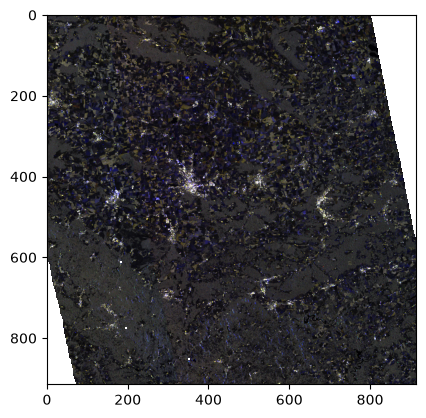

In [22]:
# Without selection, all the time steps are returned as bands
# Note: there are no `time` coordinates, so band names default to `time{n}`
img = await reader.preview(variables=["ascending:vv"])
print("Dimensions:", img.dimensions)
print("Band Names:", img.band_names)
print("Band Descriptions:", img.band_descriptions)
print("Array Shape:", img.array.shape)

imshow(img.data_as_image(), vmax=0.2)

Dimensions: ['b', 'y', 'x']
Band Names: ['b1']
Band Descriptions: ['b1']
Array Shape: (1, 915, 915)


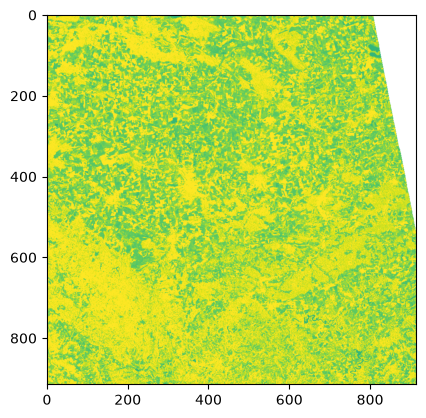

In [15]:
# Select a specific time slice
# Note: because the `time` dimension has no coordinates, selection is done by position
img = await reader.preview(variables=["ascending:vv"], sel={"time": 0})
print("Dimensions:", img.dimensions)
print("Band Names:", img.band_names)
print("Band Descriptions:", img.band_descriptions)
print("Array Shape:", img.array.shape)

imshow(img.data_as_image(), vmax=0.2)

### Multi-variable composite

Selection applies to all requested variables, which are then stacked along a new `variables` dimension.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.00058447197..76.886665].


Dimensions: ['variables', 'y', 'x']
Band Names: ['variables1', 'variables2', 'variables3']
Band Descriptions: ['descending:vv', 'descending:vh', 'descending:vv']
Array Shape: (3, 915, 915)


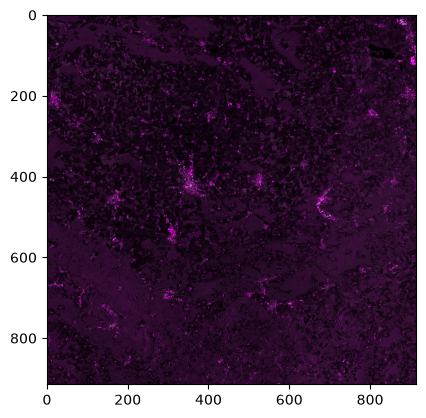

In [ ]:
# Create a VV/VH/VV composite for the second time step
img = await reader.preview(
    variables=["descending:vv", "descending:vh", "descending:vv"],
    sel={"time": 1},
)
print("Dimensions:", img.dimensions)
print("Band Names:", img.band_names)
print("Band Descriptions:", img.band_descriptions)
print("Array Shape:", img.array.shape)

imshow(img.data_as_image(), vmax=0.15)

### Temporal reduction

Instead of selecting a single time step, we can reduce the `time` dimension (here with a masked mean) to create a temporal composite.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0007721016299910843..76.9713134765625].


Dimensions: ['variables', 'y', 'x']
Band Names: ['variables1', 'variables2', 'variables3']
Band Descriptions: ['descending:vv', 'descending:vh', 'descending:vv']
Array Shape: (3, 915, 915)


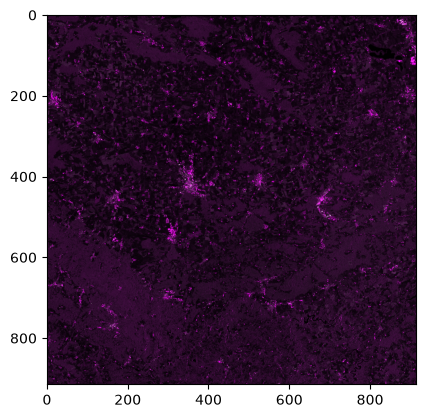

In [20]:
# Create a VV/VH/VV composite, reducing the time dimension with a (masked) mean
# `reduce` takes a list of (dimension, function) tuples
img = await reader.preview(
    variables=["descending:vv", "descending:vh", "descending:vv"],
    reduce=[("time", numpy.ma.mean)],
)
print("Dimensions:", img.dimensions)
print("Band Names:", img.band_names)
print("Band Descriptions:", img.band_descriptions)
print("Array Shape:", img.array.shape)

imshow(img.data_as_image(), vmax=0.1)